# EtherLens — live analysis on the Dataproc cluster

This notebook runs on the cluster's **PySpark** kernel (`spark` is already created).
It reads the silver and gold tables the batch jobs wrote to Cloud Storage and runs
a few Spark SQL queries live, to show that the analysis really runs on the cluster.

Data: Ethereum mainnet transactions, January 2025 (~37 M rows after cleaning).

In [1]:
BUCKET = "etherlens-parvmittal"          # change if your bucket name differs
SILVER = f"gs://{BUCKET}/silver/tx"
GOLD = f"gs://{BUCKET}/gold"

silver = spark.read.parquet(SILVER)
silver.createOrReplaceTempView("silver_tx")
print("silver rows:", silver.count())
silver.printSchema()

silver rows: 37323780
root
 |-- hash: string (nullable = true)
 |-- block_number: long (nullable = true)
 |-- ts: timestamp (nullable = true)
 |-- hour: integer (nullable = true)
 |-- dow: integer (nullable = true)
 |-- from_address: string (nullable = true)
 |-- to_address: string (nullable = true)
 |-- is_contract_creation: boolean (nullable = true)
 |-- value_eth: double (nullable = true)
 |-- gas_limit: long (nullable = true)
 |-- gas_used: long (nullable = true)
 |-- gas_price_gwei: double (nullable = true)
 |-- fee_eth: double (nullable = true)
 |-- nonce: long (nullable = true)
 |-- tx_type: long (nullable = true)
 |-- is_plain_transfer: boolean (nullable = true)
 |-- dt: date (nullable = true)



## 1. Daily activity (Spark SQL)
`dt` is the partition column, so each day is one folder (one Parquet file) in the bucket.

In [2]:
spark.sql("""
    SELECT dt, COUNT(*) AS tx, COUNT(DISTINCT from_address) AS senders,
           ROUND(SUM(value_eth), 0) AS eth_moved
    FROM silver_tx GROUP BY dt ORDER BY dt
""").show(31)

+----------+-------+-------+---------+
|        dt|     tx|senders|eth_moved|
+----------+-------+-------+---------+
|2025-01-01|1016263| 320722|1600023.0|
|2025-01-02|1071552| 361674|1597110.0|
|2025-01-03|1217785| 411170|1449236.0|
|2025-01-04|1143617| 381227| 944877.0|
|2025-01-05|1125976| 374394| 605876.0|
|2025-01-06|1191688| 383739|1539932.0|
|2025-01-07|1194112| 394879|1801667.0|
|2025-01-08|1183841| 379783|2042551.0|
|2025-01-09|1185292| 395651|2146301.0|
|2025-01-10|1173819| 392583|1475819.0|
|2025-01-11|1104340| 382146| 562980.0|
|2025-01-12|1079817| 367087| 945916.0|
|2025-01-13|1200476| 419156|2081657.0|
|2025-01-14|1210634| 446268|1315512.0|
|2025-01-15|1218194| 421647|1314722.0|
|2025-01-16|1228092| 415320|1724266.0|
|2025-01-17|1228180| 408921|1983211.0|
|2025-01-18|1222371| 381738|1699475.0|
|2025-01-19|1319437| 418252|2310157.0|
|2025-01-20|1370551| 453804|2285234.0|
|2025-01-21|1251123| 429692|2250661.0|
|2025-01-22|1255078| 430358|1960987.0|
|2025-01-23|1255202| 4426

## 2. Partition pruning
Filtering on `dt` lets Spark read only that day's file — see `PartitionFilters` in the plan.

In [3]:
spark.sql("SELECT COUNT(*) FROM silver_tx WHERE dt = '2025-01-15'").explain()
spark.sql("SELECT COUNT(*) AS tx_on_jan_15 FROM silver_tx WHERE dt = '2025-01-15'").show()

== Physical Plan ==
AdaptiveSparkPlan isFinalPlan=false
+- HashAggregate(keys=[], functions=[count(1)])
   +- Exchange SinglePartition, ENSURE_REQUIREMENTS, [plan_id=158]
      +- HashAggregate(keys=[], functions=[partial_count(1)])
         +- Project
            +- FileScan parquet [dt#16] Batched: true, DataFilters: [], Format: Parquet, Location: InMemoryFileIndex(1 paths)[gs://etherlens-parvmittal/silver/tx], PartitionFilters: [isnotnull(dt#16), (dt#16 = 2025-01-15)], PushedFilters: [], ReadSchema: struct<>




+------------+
|tx_on_jan_15|
+------------+
|     1218194|
+------------+



## 3. When is gas cheapest? (median gas price by hour of day, UTC)

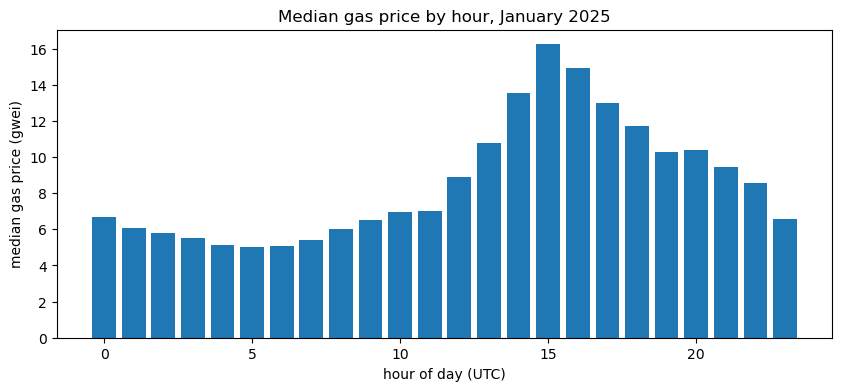

,hour,median_gwei,tx
5,5,5.021329,1447694
6,6,5.079493,1460480
4,4,5.138612,1436885


In [4]:
import matplotlib.pyplot as plt

by_hour = spark.sql("""
    SELECT hour, percentile_approx(gas_price_gwei, 0.5) AS median_gwei, COUNT(*) AS tx
    FROM silver_tx GROUP BY hour ORDER BY hour
""").toPandas()

fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(by_hour["hour"], by_hour["median_gwei"])
ax.set_xlabel("hour of day (UTC)"); ax.set_ylabel("median gas price (gwei)")
ax.set_title("Median gas price by hour, January 2025")
plt.show()
by_hour.sort_values("median_gwei").head(3)

## 4. Most central addresses (PageRank, last 7 days)

In [5]:
spark.read.parquet(f"{GOLD}/pagerank").orderBy("rank", ascending=False).show(10, truncate=False)

+------------------------------------------+------------------+
|address                                   |rank              |
+------------------------------------------+------------------+
|0xdac17f958d2ee523a2206206994597c13d831ec7|17048.869906216798|
|0xa0b86991c6218b36c1d19d4a2e9eb0ce3606eb48|6682.6233013090205|
|0x76a0e27618462bdac7a29104bdcfff4e6bfcea2d|6479.797604205688 |
|0x9a10da8ce77f26231860764a2caab36e70584c4b|5869.6028151301925|
|0xb5d85cbf7cb3ee0d56b3bb207d5fc4b82f43f511|3784.1623232434404|
|0x640cb7201810bc920835a598248c4fe4898bb5e0|2950.932710271799 |
|0x3fc91a3afd70395cd496c647d5a6cc9d4b2b7fad|2770.6546782558653|
|0xb5b1ca3496c736b225a78efa6b68c023b5375667|2168.7776121167417|
|0xeba88149813bec1cccccfdb0dacefaaa5de94cb1|2101.7938228227026|
|0x974caa59e49682cda0ad2bbe82983419a2ecc400|1808.1014660461133|
+------------------------------------------+------------------+
only showing top 10 rows



## 5. Anomaly detection (KMeans): cluster sizes and flagged addresses

In [6]:
clusters = spark.read.parquet(f"{GOLD}/address_clusters")
clusters.groupBy("cluster").count().orderBy("cluster").show()
flagged = spark.read.parquet(f"{GOLD}/flagged_addresses")
flagged.groupBy("reason").count().show()
flagged.orderBy("score", ascending=False).show(5, truncate=False)

+-------+------+
|cluster| count|
+-------+------+
|      0| 91248|
|      1|199561|
|      2|159950|
|      3|     5|
|      4| 34706|
|      5|321039|
|      6|176191|
|      7|178701|
|      8|157644|
|      9|116713|
+-------+------+

+-----------------+-----+
|           reason|count|
+-----------------+-----+
|far_from_centroid| 7412|
|     rare_cluster|    5|
+-----------------+-----+

+------------------------------------------+-----------------+------------------+
|address                                   |reason           |score             |
+------------------------------------------+-----------------+------------------+
|0x1d680ac2c4cf62dfba822a0f87e7e5cec01c9de7|rare_cluster     |233.73612731194328|
|0xaa3bb24e2b3c1f7f7ef181060ffb544b0603acb3|far_from_centroid|157.42826054948802|
|0x114b9a52be6e2dc5c99fdf051d73b9d2e4d8c4bd|far_from_centroid|152.89024423037793|
|0x6501ba9dff446180e98eca7f0e652794de752880|far_from_centroid|141.41844170974048|
|0x01822922baafb77995fd4a91c46